
# Uczenie maszynowe — zajęcia 6
## Sieć Hopfielda — pamięć asocjacyjna

**Uniwersytet Warmińsko-Mazurski w Olsztynie**  
**Semestr 5, rok akademicki 2026/2027**  
**Prowadzący: mgr inż. Adrian Albrecht**

---

## Cel zajęć

Na poprzednich zajęciach poznaliśmy regułę Hebba.

Dzisiaj wykorzystamy tę ideę do zbudowania **sieci Hopfielda** — klasycznego modelu pamięci asocjacyjnej.

Po zajęciach osoba studiująca powinna umieć:

1. wyjaśnić, czym różni się pamięć asocjacyjna od zwykłego klasyfikatora,
2. opisać strukturę klasycznej sieci Hopfielda,
3. zakodować wzorce bipolarnie,
4. wyznaczyć macierz wag za pomocą reguły Hebba,
5. wyjaśnić, dlaczego na przekątnej macierzy wag ustawiamy zera,
6. opisać aktualizację stanu neuronów,
7. wyjaśnić znaczenie funkcji energii,
8. odzyskać wzorzec z jego zaszumionej wersji,
9. omówić ograniczenia pojemności pamięci,
10. samodzielnie zaimplementować `MyHopfieldNetwork`.

> **Ważne:** implementacja `MyHopfieldNetwork` nie znajduje się w notebooku udostępnianym studentom. Jest to zadanie własne.



## Plan zajęć — 90 minut

| Czas | Temat |
|---:|---|
| 0–10 min | Pamięć asocjacyjna i idea sieci Hopfielda |
| 10–25 min | Kodowanie bipolarne i macierz wag |
| 25–40 min | Aktualizacja neuronów |
| 40–52 min | Funkcja energii i atraktory |
| 52–68 min | Zapamiętywanie i odtwarzanie wzorców 5×5 |
| 68–78 min | Szum i odzyskiwanie wzorca |
| 78–85 min | Pojemność, interferencja i ograniczenia |
| 85–90 min | Zadanie własne i podsumowanie |



# 0. Przygotowanie środowiska


In [39]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(
    precision=3,
    suppress=True
)

RANDOM_STATE = 42



# 1. Czym jest pamięć asocjacyjna?

W zwykłym klasyfikatorze pytamy:

> Do której klasy należy obserwacja?

W pamięci asocjacyjnej pytamy raczej:

> Jaki zapamiętany wzorzec najbardziej przypomina ten niepełny albo zaszumiony stan?

Przykład:

```text
zapamiętano:          podano:

#...#                 #...#
#...#                 ....#
#####                 ##.##
#...#                 #...#
#...#                 #..##
```

Chcemy, aby sieć wróciła do zapamiętanego wzorca.

Taki stabilny zapamiętany stan możemy traktować jako **atraktor**.



# 2. Struktura klasycznej sieci Hopfielda

Klasyczna sieć Hopfielda jest siecią rekurencyjną.

Każdy neuron jest połączony z pozostałymi neuronami.

Dla `N` neuronów mamy macierz wag:

$$
W
\in
\mathbb{R}^{N\times N}
$$

W klasycznej wersji:

$$
w_{ij}=w_{ji}
$$

czyli macierz wag jest symetryczna.

Dodatkowo:

$$
w_{ii}=0
$$

czyli neuron nie posiada połączenia z samym sobą.



# 3. Kodowanie bipolarne

W klasycznej sieci Hopfielda wygodne jest kodowanie:

$$
s_i \in \{-1,1\}
$$

Możemy interpretować:

```text
 1  → aktywny piksel
-1  → nieaktywny piksel
```

Dzięki temu obraz binarny można spłaszczyć do jednego wektora.


In [40]:

pattern_H = np.array([
    [ 1, -1, -1, -1,  1],
    [ 1, -1, -1, -1,  1],
    [ 1,  1,  1,  1,  1],
    [ 1, -1, -1, -1,  1],
    [ 1, -1, -1, -1,  1]
])

print(pattern_H)

print(
    "\nLiczba neuronów:",
    pattern_H.size
)


[[ 1 -1 -1 -1  1]
 [ 1 -1 -1 -1  1]
 [ 1  1  1  1  1]
 [ 1 -1 -1 -1  1]
 [ 1 -1 -1 -1  1]]

Liczba neuronów: 25


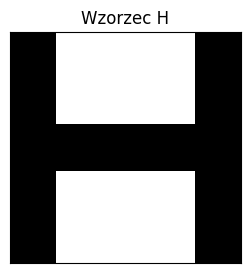

In [41]:

def show_pattern(
    pattern,
    title=None
):
    pattern = np.asarray(pattern)

    if pattern.ndim == 1:
        side = int(
            np.sqrt(pattern.size)
        )

        pattern = pattern.reshape(
            side,
            side
        )

    plt.figure(figsize=(3, 3))

    plt.imshow(
        pattern,
        cmap="binary",
        vmin=-1,
        vmax=1
    )

    plt.xticks([])
    plt.yticks([])

    if title is not None:
        plt.title(title)

    plt.show()


show_pattern(
    pattern_H,
    "Wzorzec H"
)



# 4. Reguła Hebba w sieci Hopfielda

Załóżmy najpierw, że chcemy zapamiętać jeden wzorzec:

$$
\mathbf{p}
$$

Macierz wag możemy zbudować z iloczynu zewnętrznego:

$$
\mathbf{p}\mathbf{p}^T
$$

Dla wielu wzorców:

$$
\mathbf{p}^{(1)},
\mathbf{p}^{(2)},
\dots,
\mathbf{p}^{(P)}
$$

sumujemy ich wkład:

$$
W
=
\frac{1}{N}
\sum_{\mu=1}^{P}
\mathbf{p}^{(\mu)}
\left(
\mathbf{p}^{(\mu)}
\right)^T
$$

gdzie:

- `P` — liczba zapamiętywanych wzorców,
- `N` — liczba neuronów.

Na końcu ustawiamy:

$$
w_{ii}=0
$$



## 4.1. Mały przykład

Weźmy wzorzec:

$$
\mathbf{p}
=
[1,-1,1]
$$

Iloczyn zewnętrzny:

$$
\mathbf{p}\mathbf{p}^T
$$

daje macierz `3 × 3`.


In [42]:

p = np.array([
    1,
    -1,
    1
], dtype=float)

outer = np.outer(
    p,
    p
)

print(
    "Iloczyn zewnętrzny:"
)

print(outer)


Iloczyn zewnętrzny:
[[ 1. -1.  1.]
 [-1.  1. -1.]
 [ 1. -1.  1.]]



Po wyzerowaniu przekątnej neuron nie wzmacnia bezpośrednio własnego stanu.


In [43]:

W_small = (
    np.outer(p, p)
    / len(p)
)

np.fill_diagonal(
    W_small,
    0
)

print(W_small)

print(
    "\nCzy macierz jest symetryczna?"
)

print(
    np.allclose(
        W_small,
        W_small.T
    )
)


[[ 0.    -0.333  0.333]
 [-0.333  0.    -0.333]
 [ 0.333 -0.333  0.   ]]

Czy macierz jest symetryczna?
True



# 5. Aktualizacja stanu neuronu

Dla neuronu `i` obliczamy jego lokalne pobudzenie:

$$
h_i
=
\sum_j
w_{ij}s_j
$$

Następnie:

$$
s_i^{new}
=
\operatorname{sign}(h_i)
$$

Czyli:

$$
s_i^{new}
=
1
$$

gdy:

$$
h_i>0
$$

oraz:

$$
s_i^{new}
=
-1
$$

gdy:

$$
h_i<0
$$

Jeżeli:

$$
h_i=0
$$

możemy pozostawić poprzedni stan neuronu.



## 5.1. Aktualizacja synchroniczna i asynchroniczna

### Synchroniczna

Najpierw obliczamy nowe stany wszystkich neuronów, a następnie zmieniamy je jednocześnie.

### Asynchroniczna

Aktualizujemy neurony jeden po drugim.

Nowy stan jednego neuronu może więc wpłynąć na kolejne neurony jeszcze w tej samej iteracji.

W klasycznej analizie sieci Hopfielda szczególnie ważna jest aktualizacja **asynchroniczna**, ponieważ przy symetrycznych wagach i zerowej przekątnej jest związana z monotonicznym spadkiem lub zachowaniem energii.



# 6. Funkcja energii

Dla stanu:

$$
\mathbf{s}
$$

definiujemy energię:

$$
E(\mathbf{s})
=
-\frac{1}{2}
\mathbf{s}^T
W
\mathbf{s}
$$

Intuicyjnie sieć porusza się po krajobrazie energii.

Stabilne zapamiętane wzorce powinny odpowiadać niskim wartościom energii — lokalnym minimom.

Schematycznie:

```text
energia

   \\        /\\
    \\      /  \\
     \\____/    \\____
       A           B

A i B — atraktory
```



## 6.1. Dlaczego energia jest użyteczna?

Jeżeli dla asynchronicznej aktualizacji:

$$
E_{t+1}
\leq
E_t
$$

to sieć nie „wspina się” po krajobrazie energii.

Może dojść do stabilnego stanu, w którym dalsze aktualizacje już niczego nie zmieniają.

To daje mechanizm pamięci:

```text
zaszumiony wzorzec
        ↓
kolejne aktualizacje
        ↓
spadek energii
        ↓
stabilny atraktor
```



# 7. Wzorce 5 × 5

Przygotujmy trzy wzorce:

- H,
- T,
- X.


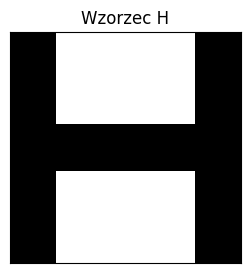

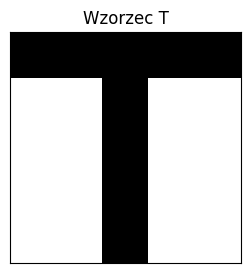

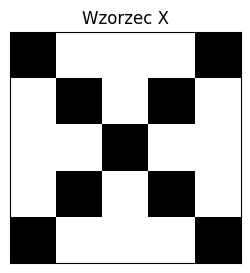

In [44]:

pattern_T = np.array([
    [ 1,  1,  1,  1,  1],
    [-1, -1,  1, -1, -1],
    [-1, -1,  1, -1, -1],
    [-1, -1,  1, -1, -1],
    [-1, -1,  1, -1, -1]
])

pattern_X = np.array([
    [ 1, -1, -1, -1,  1],
    [-1,  1, -1,  1, -1],
    [-1, -1,  1, -1, -1],
    [-1,  1, -1,  1, -1],
    [ 1, -1, -1, -1,  1]
])

patterns_2d = [
    pattern_H,
    pattern_T,
    pattern_X
]

names = [
    "H",
    "T",
    "X"
]

for name, pattern in zip(
    names,
    patterns_2d
):
    show_pattern(
        pattern,
        f"Wzorzec {name}"
    )



Każdy obraz `5 × 5` odpowiada:

$$
N=25
$$

neuronom.

Przed przekazaniem do sieci spłaszczamy obrazy do wektorów długości `25`.


In [45]:

patterns = np.array([
    pattern.ravel()
    for pattern
    in patterns_2d
])

print(
    patterns.shape
)


(3, 25)



# 8. Demonstracja własnej implementacji

Sprawdzamy, czy dostępny jest moduł:

```text
myHopfield.py
```

Gotowa implementacja nie jest częścią notebooka.


In [46]:

try:
    from myHopfield import MyHopfieldNetwork

    HAS_MY_HOPFIELD = True
    print("Znaleziono implementację.")

except ImportError:
    HAS_MY_HOPFIELD = False
    print("Nie znaleziono implementacji.")


Znaleziono implementację.


In [47]:

if HAS_MY_HOPFIELD:

    hopfield = MyHopfieldNetwork(
        update_mode="asynchronous",
        random_state=RANDOM_STATE
    )

    hopfield.fit(
        patterns
    )

    print(
        "Kształt macierzy wag:",
        hopfield.weights_.shape
    )

    print(
        "Czy macierz jest symetryczna?",
        np.allclose(
            hopfield.weights_,
            hopfield.weights_.T
        )
    )

    print(
        "Przekątna:",
        np.diag(
            hopfield.weights_
        )
    )


Kształt macierzy wag: (25, 25)
Czy macierz jest symetryczna? True
Przekątna: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0.]



# 9. Dodawanie szumu

Aby sprawdzić pamięć asocjacyjną, uszkodzimy część pikseli zapamiętanego wzorca.

Dla kodowania bipolarnego „odwrócenie piksela” oznacza:

$$
1 \leftrightarrow -1
$$


In [48]:

def add_noise(
    pattern,
    n_flips,
    random_state=42
):
    rng = np.random.default_rng(
        random_state
    )

    noisy = np.asarray(
        pattern
    ).copy().reshape(-1)

    indices = rng.choice(
        noisy.size,
        size=n_flips,
        replace=False
    )

    noisy[indices] *= -1

    return noisy


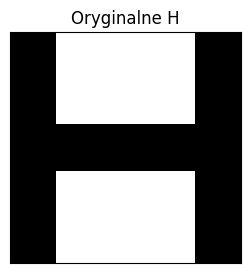

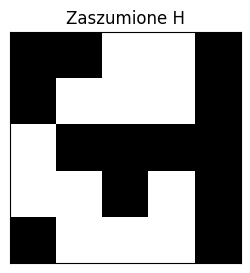

In [49]:

noisy_H = add_noise(
    pattern_H,
    n_flips=4,
    random_state=RANDOM_STATE
)

show_pattern(
    pattern_H,
    "Oryginalne H"
)

show_pattern(
    noisy_H,
    "Zaszumione H"
)



# 10. Odtwarzanie wzorca

Podajemy zaszumiony stan do sieci.

Sieć wykonuje kolejne aktualizacje, aż:

- osiągnie stan stabilny,
- albo osiągniemy maksymalną liczbę iteracji.


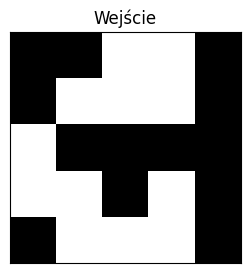

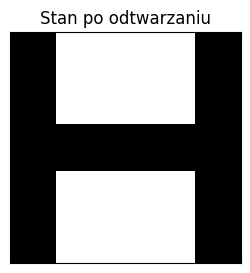

Liczba iteracji: 2
Stan stabilny: True
Czy odzyskano H? True


In [50]:

if HAS_MY_HOPFIELD:

    result = hopfield.predict(
        noisy_H,
        max_iterations=20,
        return_history=True
    )

    recalled_H = result[
        "state"
    ]

    show_pattern(
        noisy_H,
        "Wejście"
    )

    show_pattern(
        recalled_H,
        "Stan po odtwarzaniu"
    )

    print(
        "Liczba iteracji:",
        result["iterations"]
    )

    print(
        "Stan stabilny:",
        result["converged"]
    )

    print(
        "Czy odzyskano H?",
        np.array_equal(
            recalled_H,
            pattern_H.ravel()
        )
    )



# 11. Energia podczas odtwarzania

Jeżeli wykorzystujemy aktualizację asynchroniczną, warto obserwować energię sieci.


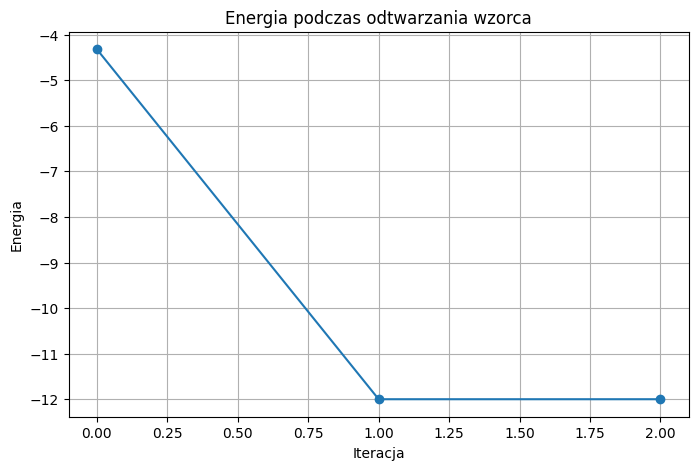

Energie: [ -4.32 -12.   -12.  ]


In [51]:

if HAS_MY_HOPFIELD:

    energies = result[
        "energies"
    ]

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        range(len(energies)),
        energies,
        marker="o"
    )

    plt.xlabel("Iteracja")
    plt.ylabel("Energia")
    plt.title(
        "Energia podczas odtwarzania wzorca"
    )
    plt.grid()
    plt.show()

    print(
        "Energie:",
        energies
    )



### Pytania

1. Czy energia wzrosła podczas odtwarzania?
2. Czy po osiągnięciu wzorca stabilnego kolejne aktualizacje są potrzebne?
3. Czy najniższa energia zawsze musi oznaczać wzorzec, który chcieliśmy odzyskać?

Ostatnie pytanie jest ważne.

Sieć może posiadać również **stany pasożytnicze** (*spurious states*), które nie były jawnie zapamiętywane.



# 12. Kolejne poziomy szumu

Sprawdźmy, co dzieje się po odwróceniu coraz większej liczby pikseli.


In [52]:

if HAS_MY_HOPFIELD:

    for n_flips in [
        1,
        3,
        5,
        7,
        9
    ]:
        noisy = add_noise(
            pattern_H,
            n_flips=n_flips,
            random_state=RANDOM_STATE
        )

        recalled = hopfield.predict(
            noisy,
            max_iterations=20
        )

        recovered = np.array_equal(
            recalled,
            pattern_H.ravel()
        )

        print(
            f"Odwrócone piksele: {n_flips:2d} "
            f"→ odzyskano H: {recovered}"
        )


Odwrócone piksele:  1 → odzyskano H: True
Odwrócone piksele:  3 → odzyskano H: True
Odwrócone piksele:  5 → odzyskano H: True
Odwrócone piksele:  7 → odzyskano H: True
Odwrócone piksele:  9 → odzyskano H: False



Nie oczekujemy, że sieć zawsze odtworzy poprawny wzorzec.

Im bardziej wejście oddala się od zapamiętanego atraktora, tym większa szansa, że:

- sieć trafi do innego zapamiętanego wzorca,
- trafi do stanu pasożytniczego,
- w pewnych trybach aktualizacji nie osiągnie oczekiwanego stanu.



# 13. Synchronicznie czy asynchronicznie?

Klasyczna funkcja energii daje szczególnie wygodną interpretację dla **aktualizacji asynchronicznej**.

Przy aktualizacji synchronicznej wszystkie neurony zmieniają stan jednocześnie.

Może wtedy wystąpić np. oscylacja pomiędzy stanami.

Sprawdźmy oba tryby na tym samym wejściu.


In [53]:

if HAS_MY_HOPFIELD:

    async_result = hopfield.predict(
        noisy_H,
        max_iterations=10,
        update_mode="asynchronous",
        return_history=True
    )

    sync_result = hopfield.predict(
        noisy_H,
        max_iterations=10,
        update_mode="synchronous",
        return_history=True
    )

    comparison = pd.DataFrame({
        "asynchroniczna": (
            async_result["energies"]
        )
    })

    print(
        "Tryb asynchroniczny:"
    )

    print(
        "iteracje =",
        async_result["iterations"],
        ", stabilny =",
        async_result["converged"]
    )

    print(
        "\nTryb synchroniczny:"
    )

    print(
        "iteracje =",
        sync_result["iterations"],
        ", stabilny =",
        sync_result["converged"]
    )


Tryb asynchroniczny:
iteracje = 2 , stabilny = True

Tryb synchroniczny:
iteracje = 2 , stabilny = True



# 14. Pojemność pamięci

Sieć Hopfielda nie może przechowywać dowolnej liczby wzorców bez pogorszenia działania.

Dla klasycznego modelu i losowych, słabo skorelowanych wzorców często podaje się orientacyjne przybliżenie:

$$
P_{max}
\approx
0.138N
$$

Nie jest to twarda granica dla każdego zbioru danych.

Pojemność zależy między innymi od:

- liczby neuronów,
- podobieństwa pomiędzy wzorcami,
- sposobu kodowania,
- reguły uczenia,
- sposobu aktualizacji,
- poziomu akceptowanego błędu.

Dla:

$$
N=25
$$

nie powinniśmy oczekiwać bezproblemowego przechowywania bardzo wielu dowolnych wzorców.



## 14.1. Interferencja

Macierz wag jest sumą wkładów wszystkich wzorców:

$$
W
=
\frac{1}{N}
\sum_{\mu}
\mathbf{p}^{(\mu)}
\left(
\mathbf{p}^{(\mu)}
\right)^T
$$

Wzorce mogą więc wpływać na siebie nawzajem.

Jeżeli są bardzo podobne albo jest ich zbyt dużo, ich reprezentacje zaczynają się **nakładać**.

To nazywamy interferencją.



# 15. Zadanie własne — `MyHopfieldNetwork`

Przygotuj własny plik:

```text
myHopfield.py
```

i zaimplementuj klasę:

```python
class MyHopfieldNetwork:
    ...
```

## Minimalne wymagania

Klasa powinna posiadać przynajmniej:

```python
fit(patterns)
predict(state)
energy(state)
```

oraz przechowywać:

```python
weights_
```

## `fit(patterns)`

Metoda powinna:

1. przyjąć wzorce bipolarne,
2. zbudować macierz wag zgodnie z regułą Hebba,
3. zapewnić symetrię macierzy,
4. ustawić przekątną na zero.

Wykorzystaj:

$$
W
=
\frac{1}{N}
\sum_{\mu=1}^{P}
\mathbf{p}^{(\mu)}
\left(
\mathbf{p}^{(\mu)}
\right)^T
$$

## `predict(state)`

Metoda powinna:

1. przyjąć początkowy stan,
2. wykonywać kolejne aktualizacje neuronów,
3. zakończyć działanie po osiągnięciu stanu stabilnego albo limitu iteracji,
4. zwrócić stan końcowy.

Minimalnie zaimplementuj aktualizację **asynchroniczną**.

## `energy(state)`

Oblicz:

$$
E(\mathbf{s})
=
-\frac{1}{2}
\mathbf{s}^T
W
\mathbf{s}
$$

## Dodatkowo

Warto zwracać lub zapisywać:

- historię kolejnych stanów,
- historię energii,
- liczbę iteracji,
- informację o osiągnięciu stanu stabilnego.

> Nie korzystamy z gotowej implementacji sieci Hopfielda jako rozwiązania zadania.



# 16. Testy własnej implementacji

Po napisaniu klasy sprawdź:

### Test 1

Czy:

```python
weights_.shape
```

ma wartość:

```text
(N, N)
```

### Test 2

Czy:

```python
weights_
```

jest macierzą symetryczną?

### Test 3

Czy:

```python
diag(weights_)
```

składa się z zer?

### Test 4

Czy zapamiętany wzorzec pozostaje stabilny po podaniu go bez szumu?

### Test 5

Czy sieć potrafi odtworzyć wzorzec po zmianie kilku bitów?

### Test 6

Czy przy asynchronicznej aktualizacji energia ma tendencję do niewzrastania?

### Test 7

Co dzieje się po dodawaniu kolejnych zapamiętywanych wzorców?

### Test 8

Co dzieje się, gdy wzorce są do siebie bardzo podobne?



# 17. Gotowa implementacja z biblioteki — `hopfieldkit`

Do tej pory pracowaliśmy z własną implementacją sieci Hopfielda.

Na koniec warto zobaczyć również gotową implementację biblioteczną.

W Pythonie nie ma klasycznej sieci Hopfielda bezpośrednio w `scikit-learn`, ale istnieją osobne biblioteki. Jedną z nich jest:

```text
hopfieldkit
```

Instalacja:

```bash
pip install hopfieldkit
```

Biblioteka udostępnia klasyczną pamięć asocjacyjną Hopfielda z uczeniem Hebba.

W tej części nie analizujemy kodu biblioteki. Traktujemy ją jak gotową implementację algorytmu:

1. przygotowujemy dane,
2. tworzymy model,
3. uczymy model,
4. wykonujemy odtwarzanie,
5. interpretujemy wynik.


In [54]:
%pip install hopfieldkit

Note: you may need to restart the kernel to use updated packages.



## 17.1. Import

Sprawdzamy, czy biblioteka jest zainstalowana.

Jeżeli nie jest dostępna, pozostała część notebooka nadal działa.


In [55]:

try:
    from hopfieldkit import HopfieldNetwork

    HAS_HOPFIELDKIT = True
    print("Znaleziono bibliotekę hopfieldkit.")

except ImportError:
    HAS_HOPFIELDKIT = False

    print(
        "Nie znaleziono biblioteki hopfieldkit. "
        "Można ją zainstalować poleceniem: "
        "pip install hopfieldkit"
    )


Znaleziono bibliotekę hopfieldkit.



## 17.2. Utworzenie i nauczenie sieci

Mamy już przygotowaną macierz:

```python
patterns
```

Dla obrazów `5 × 5` liczba neuronów wynosi:

$$
N=25
$$


In [56]:

if HAS_HOPFIELDKIT:

    library_hopfield = HopfieldNetwork(
        n_units=patterns.shape[1]
    )

    library_hopfield.fit(
        patterns
    )

    print(
        "Nauczono gotową sieć Hopfielda."
    )


Nauczono gotową sieć Hopfielda.



## 17.3. Odtwarzanie zaszumionego wzorca

Używamy dokładnie tego samego zaszumionego `H`, które wcześniej przekazaliśmy do własnej implementacji.


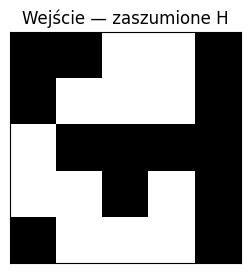

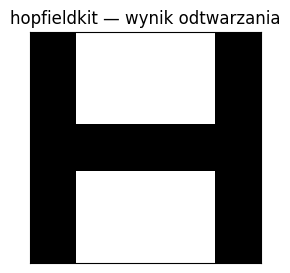

Czy odzyskano H? True


In [57]:

if HAS_HOPFIELDKIT:

    recovered_library = (
        library_hopfield.recall(
            noisy_H,
            order="sequential"
        )
    )

    show_pattern(
        noisy_H,
        "Wejście — zaszumione H"
    )

    show_pattern(
        recovered_library,
        "hopfieldkit — wynik odtwarzania"
    )

    print(
        "Czy odzyskano H?",
        np.array_equal(
            recovered_library,
            pattern_H.ravel()
        )
    )



## 17.4. Porównanie z własną implementacją

Jeżeli mamy dostępne oba modele, możemy porównać końcowy stan zwrócony przez każdą implementację.


Czy oba wyniki są identyczne? True


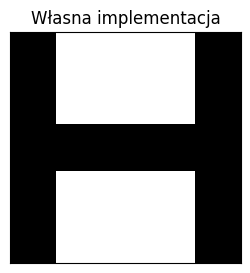

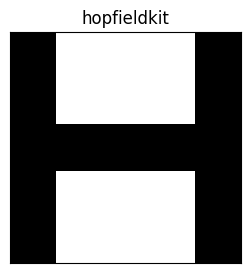

In [58]:

if HAS_MY_HOPFIELD and HAS_HOPFIELDKIT:

    own_result = hopfield.predict(
        noisy_H,
        max_iterations=20
    )

    library_result = (
        library_hopfield.recall(
            noisy_H,
            order="sequential"
        )
    )

    print(
        "Czy oba wyniki są identyczne?",
        np.array_equal(
            own_result,
            library_result
        )
    )

    show_pattern(
        own_result,
        "Własna implementacja"
    )

    show_pattern(
        library_result,
        "hopfieldkit"
    )



## 17.5. Co daje nam wcześniejsza własna implementacja?

Gotowa biblioteka pozwala użyć algorytmu w kilku liniach:

```python
network = HopfieldNetwork(
    n_units=25
)

network.fit(
    patterns
)

recovered = network.recall(
    corrupted,
    order="sequential"
)
```

To jest wygodne, ale ukrywa mechanizm działania.

Po napisaniu `MyHopfieldNetwork` wiemy już, co dzieje się wewnątrz:

```text
wzorce
   ↓
reguła Hebba
   ↓
macierz wag
   ↓
stan początkowy
   ↓
lokalne pobudzenia neuronów
   ↓
kolejne aktualizacje
   ↓
zmiana energii
   ↓
stan stabilny
```

Dlatego kolejność na zajęciach jest celowa:

> **najpierw rozumiemy i implementujemy algorytm, a dopiero potem korzystamy z gotowej biblioteki.**



## 17.6. Pytania do porównania

1. Które elementy algorytmu ukrywa metoda `fit()`?
2. Które elementy ukrywa metoda `recall()`?
3. Czy identyczny wynik oznacza, że obie implementacje wykonują każdy krok identycznie?
4. Dlaczego mimo istnienia biblioteki warto było wcześniej napisać własną implementację?
5. Kiedy w praktyce wygodniej jest użyć gotowej biblioteki?



# 18. Pytania podsumowujące

1. Czym jest pamięć asocjacyjna?
2. Czym różni się sieć Hopfielda od zwykłego klasyfikatora?
3. Jak kodujemy stany neuronów?
4. Jak wygląda macierz wag?
5. Dlaczego powinna być symetryczna?
6. Dlaczego ustawiamy zerową przekątną?
7. Jak wykorzystujemy regułę Hebba do zapamiętywania wzorców?
8. Co oznacza iloczyn zewnętrzny wzorca przez samego siebie?
9. Jak wygląda aktualizacja pojedynczego neuronu?
10. Czym różni się aktualizacja synchroniczna od asynchronicznej?
11. Co oznacza funkcja energii?
12. Dlaczego stabilny stan można interpretować jako atraktor?
13. Dlaczego zaszumiony wzorzec może wrócić do zapamiętanego wzorca?
14. Czy sieć zawsze odzyska właściwy wzorzec?
15. Czym są stany pasożytnicze?
16. Co oznacza interferencja pomiędzy wzorcami?
17. Od czego zależy pojemność pamięci?
18. Dlaczego dodawanie coraz większej liczby wzorców może pogarszać odtwarzanie?
19. Czy zwiększenie liczby iteracji zawsze rozwiąże problem błędnego odtworzenia?
20. Jaki jest związek sieci Hopfielda z regułą Hebba?



# 19. Najważniejsze wnioski

> **Sieć Hopfielda jest pamięcią asocjacyjną — potrafi odtworzyć zapamiętany wzorzec na podstawie niepełnego lub zaszumionego wejścia.**

> **Macierz wag może zostać zbudowana z zapamiętywanych wzorców za pomocą reguły Hebba.**

> **Zapamiętane wzorce zachowują się jak atraktory w przestrzeni stanów.**

> **Funkcja energii pomaga opisać dynamikę sieci i jej zbieżność.**

> **Pojemność sieci jest ograniczona, a wzorce mogą wzajemnie na siebie oddziaływać.**

Na kolejnych zajęciach przechodzimy do **drzew decyzyjnych**.
